# Predicting the energy use of Seattle buildings
Day 2 assignment, supervised learning

Chloe Hraibeh, Jeff El Khoury, Luca Obejdeanu
AI Methods I, IAAC MaAI 2026/27

### Use case
An architect is doing a feasibility study for a new building in Seattle and wants a first idea of how much energy it will use per m2, before anything is designed in detail. They only know things like the use of the building, its size, the number of floors, the year and the neighborhood.

The costly mistake is underestimating: if the model says a building will use little energy and it ends up using a lot, the bills are higher and the building can miss the city's energy targets.

### Problem
- type: regression
- target: `site_eui_kwh_m2` (energy used per m2 in a year), on a log10 scale because it's very skewed
- metrics: we compare and tune the models with R2 on the log scale. We also report the MAE as a typical % error (easier to read for an architect) and check how often the model underestimates.

Data: the clean table from our Day 1 assignment (3,211 buildings).

# 0. Setup

In [1]:
#libraries
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, KFold, cross_validate, validation_curve, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.inspection import permutation_importance

In [2]:
#folders (one level up from the notebook)
DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
MODEL_DIR = Path("..") / "models"
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

#display options and plot style
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

#seed for anything random
RANDOM_STATE = 42

## 0.1 Load the clean data from Day 1
We read the clean table directly from our Day 1 repository and keep a copy in `data/`.

In [3]:
#clean table from the day 1 repo (fixed to one commit so it can't change)
url = "https://raw.githubusercontent.com/iaac-maai/6-day1-assignment/9734900/data/seattle_buildings_clean.csv"
df = pd.read_csv(url)

clean_path = DATA_DIR / "seattle_buildings_clean.csv"
df.to_csv(clean_path, index=False)

print(df.shape)
df.head()

(3211, 23)


,building_id,neighborhood,latitude,longitude,building_type,primary_property_type,use_group,year_built,building_age,number_of_buildings,number_of_floors,gfa_m2,gfa_per_floor_m2,parking_share,site_eui_kwh_m2,energystar_score,gas_share,ghg_kg_m2,total_ghg,site_energy_use,electricity,natural_gas,steam_use
0,1,DOWNTOWN,47.612,-122.338,Nonresidential,Hotel,Other,1927,89,1.000,12.000,"8,215.795",684.650,0.000,257.731,60.000,0.177,30.462,249.980,"7,226,362.500","3,946,027.000","1,276,453.000","2,003,882.000"
1,2,DOWNTOWN,47.613,-122.334,Nonresidential,Hotel,Other,1996,20,1.000,11.000,"8,222.113",747.465,0.145,299.056,61.000,0.613,30.785,295.860,"8,387,933.000","3,242,851.000","5,145,082.000",0.000
2,3,DOWNTOWN,47.614,-122.338,Nonresidential,Hotel,Other,1969,47,1.000,41.000,"70,549.894","1,720.729",0.206,302.842,43.000,0.021,23.573,"2,089.280","72,587,024.000","49,526,664.000","1,493,800.000","21,566,554.000"
3,5,DOWNTOWN,47.614,-122.337,Nonresidential,Hotel,Other,1926,90,1.000,10.000,"5,696.820",569.682,0.000,349.530,56.000,0.267,50.267,286.430,"6,794,584.000","2,768,924.000","1,811,213.000","2,214,446.250"
4,8,DOWNTOWN,47.614,-122.340,Nonresidential,Hotel,Other,1980,36,1.000,18.000,"10,551.937",586.219,0.353,362.148,75.000,0.621,31.000,505.010,"14,172,606.000","5,368,607.000","8,803,998.000",0.000


# 1. Features, leakage and split

### Inputs (what the architect knows before building)
- `primary_property_type`, `building_type`: the use and the city category
- `neighborhood`, `latitude`, `longitude`: location
- `year_built`, `number_of_floors`, `number_of_buildings`
- `gfa_m2`, `gfa_per_floor_m2`, `parking_share`: size and shape

### Removed and why
| Column | Why |
|---|---|
| `site_energy_use`, `electricity`, `natural_gas`, `steam_use` | they come from the energy bills, the same bills as the target (leakage) |
| `gas_share` | calculated from the bills |
| `has_gas` | also comes from the gas bills (gas used, not the heating system planned), so we only test it in a separate experiment (3.1) |
| `ghg_kg_m2`, `total_ghg` | emissions are calculated from the energy use (leakage) |
| `energystar_score` | the score is calculated from the energy use (leakage) |
| `building_id` | just an id |
| `building_age`, `use_group` | the same info as `year_built` and `primary_property_type` |

In [4]:
#gas yes/no, only for the experiment in 3.1 (not an input of the main model)
df["has_gas"] = (df["natural_gas"] > 0).astype(float)

#missing gas values stay missing instead of counting as no gas
df.loc[df["natural_gas"].isna(), "has_gas"] = np.nan

print(df["has_gas"].value_counts(dropna=False))

has_gas
1.000    2009
0.000    1198
NaN         4
Name: count, dtype: int64


In [5]:
#input columns
nominal_columns = ["primary_property_type", "building_type", "neighborhood"]
numeric_columns = ["year_built", "number_of_floors", "number_of_buildings", "gfa_m2",
                   "gfa_per_floor_m2", "parking_share", "latitude", "longitude"]
feature_columns = nominal_columns + numeric_columns

X = df[feature_columns]
y = np.log10(df["site_eui_kwh_m2"])

print(X.shape, y.shape)

(3211, 11) (3211,)


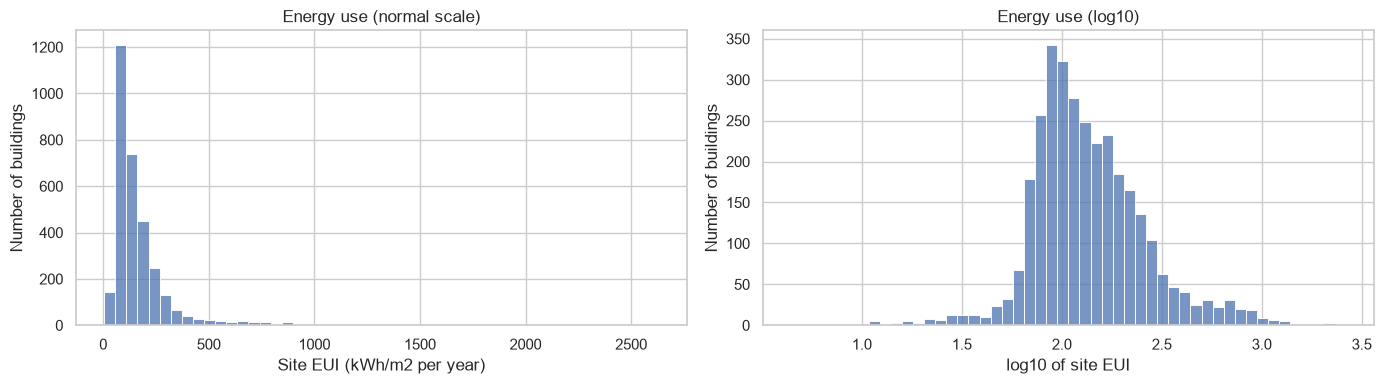

In [6]:
#target before and after the log
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df["site_eui_kwh_m2"], bins=50, ax=axes[0])
axes[0].set_title("Energy use (normal scale)")
axes[0].set_xlabel("Site EUI (kWh/m2 per year)")
axes[0].set_ylabel("Number of buildings")

sns.histplot(y, bins=50, ax=axes[1])
axes[1].set_title("Energy use (log10)")
axes[1].set_xlabel("log10 of site EUI")
axes[1].set_ylabel("Number of buildings")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_target_log.png", dpi=150, bbox_inches="tight")
plt.show()

On the normal scale almost all buildings are squeezed on the left and a few use a huge amount (data centers, supermarkets). With log10 it looks like a bell, so the model doesn't get pulled around by the few extreme ones. On the log scale 10 kWh/m2 is 1, 100 is 2 and 1,000 is 3, so one step up means 10 times more energy. At the end we turn the predictions back into kWh/m2.

In [7]:
#train / test split, the test set stays locked until section 5
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f"Train: {len(X_train)} buildings")
print(f"Test: {len(X_test)} buildings")

Train: 2568 buildings
Test: 643 buildings


# 2. Preprocessing pipeline
- numbers: missing values filled with the median, then scaled (needed for Ridge and KNN, not for trees)
- categories: missing values filled with the most common one, then one-hot encoded. All 3 are nominal (no order), so one-hot and not ordinal. `building_type` has low / mid / high-rise in it, but also nonresidential, campus and schools, so there is no real order.

Everything is inside one `Pipeline`, so in cross-validation the medians and the categories are learned only from the training folds (no leakage).

In [8]:
def make_pipeline(model, numeric=numeric_columns, scale=True):
    """Preprocessing + model in one pipeline.

    Args:
        model: any scikit-learn regression model
        numeric (list): numeric input columns
        scale (bool): True for linear models and KNN, False for trees

    Returns:
        Pipeline: preprocessing and model together
    """
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale == True:
        numeric_steps.append(("scaler", StandardScaler()))

    nominal_steps = [("imputer", SimpleImputer(strategy="most_frequent")),
                     ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]

    preprocessing = ColumnTransformer([
        ("num", Pipeline(numeric_steps), numeric),
        ("nom", Pipeline(nominal_steps), nominal_columns),
    ])
    return Pipeline([("preprocessing", preprocessing), ("model", model)])

# 3. Model comparison
5-fold cross-validation on the training set only, same folds and same metrics for every model.

In [9]:
#same 5 folds for every model
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pipelines = {
    "Baseline (mean)": make_pipeline(DummyRegressor()),
    "Ridge": make_pipeline(Ridge(alpha=1.0)),
    "KNN (k=10)": make_pipeline(KNeighborsRegressor(n_neighbors=10)),
    "Decision tree": make_pipeline(DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE), scale=False),
    "Random forest": make_pipeline(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE), scale=False),
    "Gradient boosting": make_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE), scale=False),
}

In [10]:
#cross-validation of every model
rows_list = []
for name, pipeline in pipelines.items():
    start = time.time()
    scores = cross_validate(pipeline, X_train, y_train, cv=kf,
                            scoring=["r2", "neg_mean_absolute_error"], n_jobs=-1)
    mae_log = -scores["test_neg_mean_absolute_error"]
    row = {
        "model": name,
        "R2 mean": scores["test_r2"].mean(),
        "R2 std": scores["test_r2"].std(),
        "MAE log mean": mae_log.mean(),
        "MAE log std": mae_log.std(),
        "typical error (%)": (10 ** mae_log.mean() - 1) * 100,
        "fit time (s)": scores["fit_time"].mean(),
    }
    rows_list.append(row)
    print(f"{name} done in {time.time() - start:.1f} s")

results_df = pd.DataFrame(rows_list).set_index("model")
results_df = results_df.sort_values("R2 mean", ascending=False)
results_df

Baseline (mean) done in 1.5 s
Ridge done in 0.8 s
KNN (k=10) done in 0.8 s
Decision tree done in 0.1 s
Random forest done in 1.7 s
Gradient boosting done in 0.3 s


,R2 mean,R2 std,MAE log mean,MAE log std,typical error (%),fit time (s)
model,,,,,,
Random forest,0.414,0.031,0.159,0.002,44.087,1.599
Ridge,0.386,0.036,0.166,0.006,46.484,0.011
Gradient boosting,0.334,0.050,0.168,0.006,47.324,0.223
Decision tree,0.270,0.073,0.177,0.005,50.473,0.013
KNN (k=10),0.238,0.023,0.178,0.005,50.728,0.009
Baseline (mean),-0.001,0.001,0.219,0.006,65.443,0.017


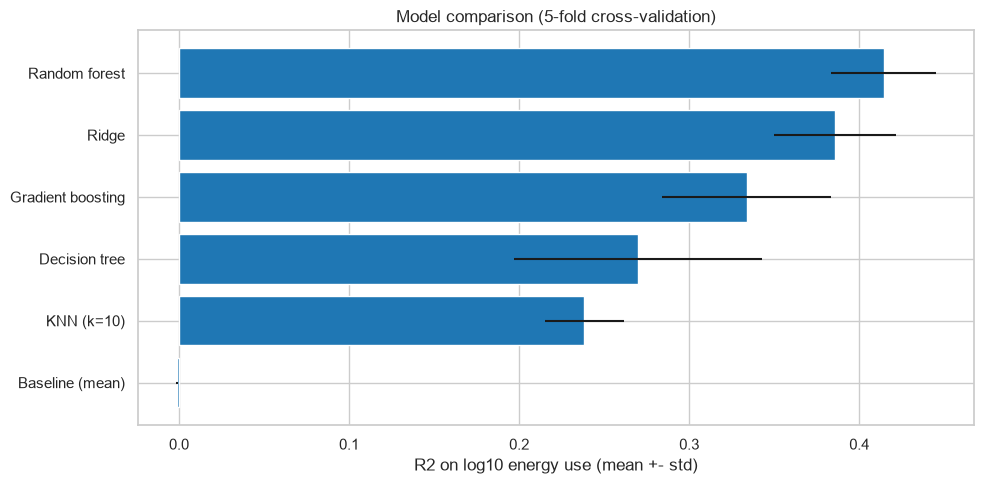

In [11]:
#R2 of each model with the std between folds
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(results_df.index, results_df["R2 mean"], xerr=results_df["R2 std"], color="tab:blue")
ax.invert_yaxis()
ax.set_title("Model comparison (5-fold cross-validation)")
ax.set_xlabel("R2 on log10 energy use (mean +- std)")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

All models beat the baseline by a lot (65% typical error). Random forest is the best (R2 0.41, about 44% error), Ridge is close (0.39) and way faster. The gap between them is about the size of the std between folds, so it's almost a tie. KNN and the single decision tree are the weakest. We keep the random forest and tune it.

## 3.1 Experiment: would knowing about gas help?
The main model doesn't use gas. Here we add `has_gas` to a copy of the training table and compare the two best models with and without it, same folds.

In [12]:
#copy of the training table with has_gas added
X_train_gas = X_train.copy()
X_train_gas["has_gas"] = df.loc[X_train.index, "has_gas"]
numeric_with_gas = numeric_columns + ["has_gas"]

#cross-validated R2 with has_gas
ridge_gas = cross_validate(make_pipeline(Ridge(alpha=1.0), numeric=numeric_with_gas),
                           X_train_gas, y_train, cv=kf, scoring="r2")
forest_gas = cross_validate(make_pipeline(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
                                          numeric=numeric_with_gas, scale=False),
                            X_train_gas, y_train, cv=kf, scoring="r2", n_jobs=-1)

gas_df = pd.DataFrame({
    "without has_gas": [results_df.loc["Ridge", "R2 mean"], results_df.loc["Random forest", "R2 mean"]],
    "with has_gas": [ridge_gas["test_score"].mean(), forest_gas["test_score"].mean()],
}, index=["Ridge", "Random forest"])
gas_df

,without has_gas,with has_gas
Ridge,0.386,0.441
Random forest,0.414,0.465


With gas both models get better, R2 goes up by about 0.05, so gas does carry information. But in this data it comes from the gas bills (gas actually used), not from the heating system planned in the design, so using it would be a bit like peeking at the answer. That's why the main model stays without it.

# 4. Diagnosis and tuning

## 4.1 Validation curve
How deep can the trees of the random forest be before it starts to overfit?

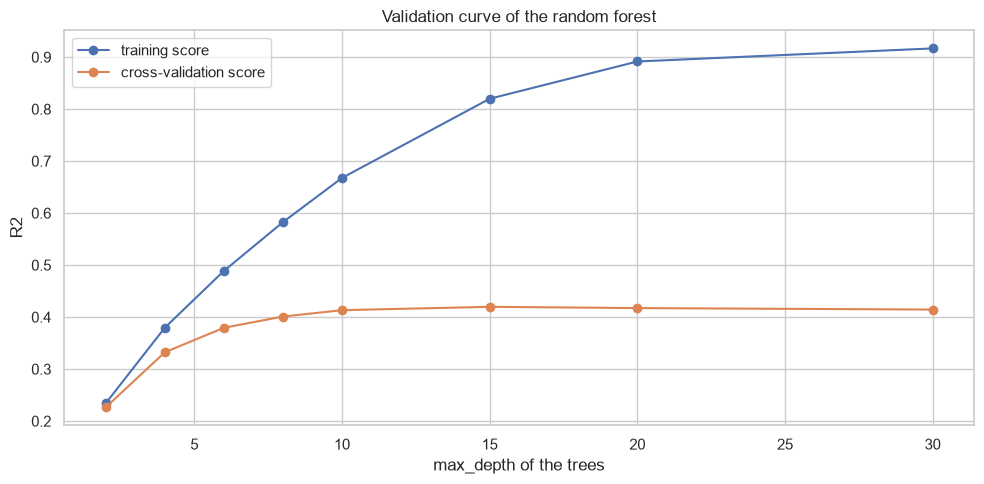

,train R2,cv R2
2,0.234,0.226
4,0.379,0.332
6,0.489,0.379
8,0.583,0.401
10,0.668,0.413
15,0.820,0.420
20,0.891,0.417
30,0.917,0.414


In [13]:
#train and cross-validation R2 for different tree depths
depths = [2, 4, 6, 8, 10, 15, 20, 30]
train_scores, cv_scores = validation_curve(
    make_pipeline(RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE), scale=False),
    X_train, y_train,
    param_name="model__max_depth",
    param_range=depths,
    cv=kf, scoring="r2", n_jobs=-1,
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(depths, train_scores.mean(axis=1), marker="o", label="training score")
ax.plot(depths, cv_scores.mean(axis=1), marker="o", label="cross-validation score")
ax.set_title("Validation curve of the random forest")
ax.set_xlabel("max_depth of the trees")
ax.set_ylabel("R2")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "03_validation_curve.png", dpi=150, bbox_inches="tight")
plt.show()

curve_df = pd.DataFrame({"train R2": train_scores.mean(axis=1), "cv R2": cv_scores.mean(axis=1)}, index=depths)
curve_df

With shallow trees (depth 2 to 4) both scores are low, that's underfitting. From depth 15 the cross-validation score stops going up (around 0.42) while the training score keeps climbing to 0.92, so deeper trees just memorize the training buildings. The gap between the two is big, so the forest overfits quite a bit, but shallower trees don't do better on new buildings either.

## 4.2 Grid search on the random forest

In [14]:
#a few settings of the random forest
param_grid = {
    "model__min_samples_leaf": [1, 3, 5, 10],
    "model__max_features": [0.3, 0.5, 1.0],
}

start = time.time()
grid_search = GridSearchCV(
    make_pipeline(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE), scale=False),
    param_grid,
    cv=kf,
    scoring="r2",
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)

print(f"Done in {time.time() - start:.0f} s")
print("Best settings:", grid_search.best_params_)
print(f"Best cross-validated R2: {grid_search.best_score_:.3f}")
print(f"Default random forest: {results_df.loc['Random forest', 'R2 mean']:.3f}")

Done in 9 s
Best settings: {'model__max_features': 0.3, 'model__min_samples_leaf': 1}
Best cross-validated R2: 0.421
Default random forest: 0.414


The best settings give 0.421 against 0.414 with the default ones. That's a really small gain, smaller than the std between folds, so tuning doesn't change much here. We keep the tuned model since it's not worse.

# 5. Final evaluation on the test set (once!)
The grid search already retrained the best random forest on the whole training set. Now we use the test set for the first and only time.

In [15]:
#predictions on the test set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

#back to kWh/m2
y_test_kwh = 10 ** y_test
y_pred_kwh = 10 ** y_pred

test_r2 = r2_score(y_test, y_pred)
test_mae = mean_absolute_error(y_test_kwh, y_pred_kwh)
test_rmse = root_mean_squared_error(y_test_kwh, y_pred_kwh)
test_mape = mean_absolute_percentage_error(y_test_kwh, y_pred_kwh) * 100
typical_error = (10 ** mean_absolute_error(y_test, y_pred) - 1) * 100

print(f"R2 (log10): {test_r2:.3f}   (cross-validation: {grid_search.best_score_:.3f})")
print(f"Typical error: {typical_error:.0f}%")
print(f"MAE: {test_mae:.0f} kWh/m2")
print(f"RMSE: {test_rmse:.0f} kWh/m2")
print(f"MAPE: {test_mape:.0f}%")

R2 (log10): 0.387   (cross-validation: 0.421)
Typical error: 45%
MAE: 68 kWh/m2
RMSE: 167 kWh/m2
MAPE: 47%


In [16]:
#baseline on the test set, to compare
baseline = make_pipeline(DummyRegressor())
baseline.fit(X_train, y_train)
y_base = baseline.predict(X_test)
baseline_mae = mean_absolute_error(y_test_kwh, 10 ** y_base)
print(f"Baseline MAE: {baseline_mae:.0f} kWh/m2")

Baseline MAE: 89 kWh/m2


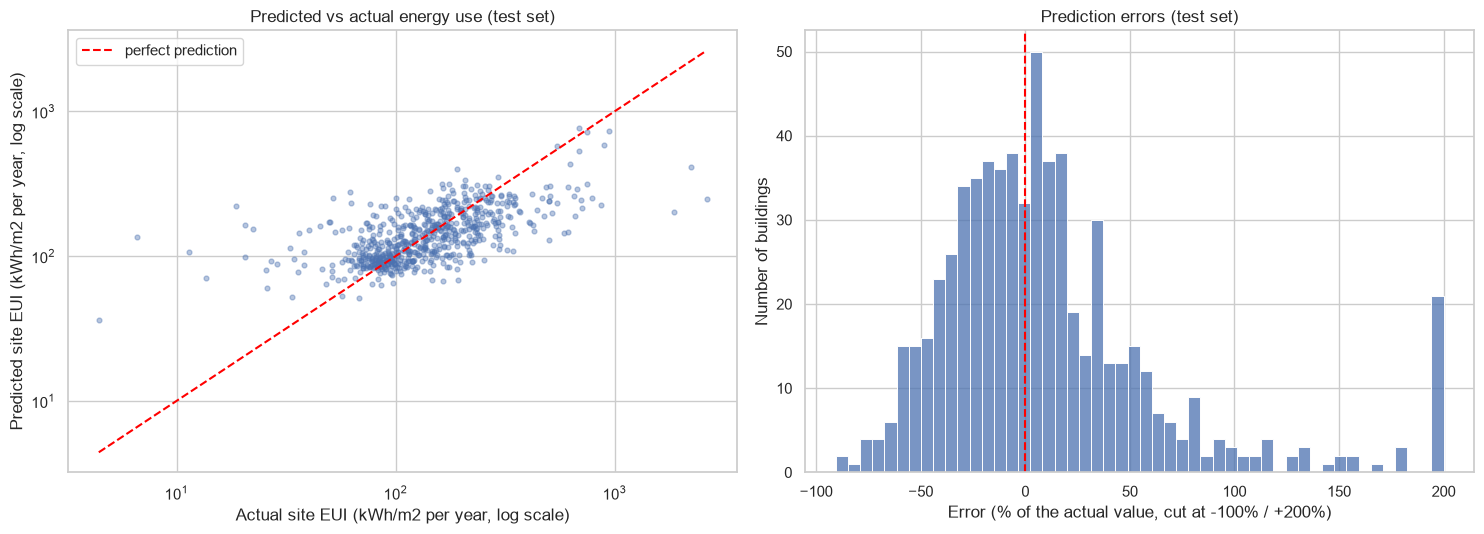

In [17]:
#predicted vs actual, and the errors in %
percent_error = (y_pred_kwh - y_test_kwh) / y_test_kwh * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].scatter(y_test_kwh, y_pred_kwh, alpha=0.4, s=12)
limits = [y_test_kwh.min(), y_test_kwh.max()]
axes[0].plot(limits, limits, color="red", linestyle="--", label="perfect prediction")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Predicted vs actual energy use (test set)")
axes[0].set_xlabel("Actual site EUI (kWh/m2 per year, log scale)")
axes[0].set_ylabel("Predicted site EUI (kWh/m2 per year, log scale)")
axes[0].legend()

sns.histplot(percent_error.clip(-100, 200), bins=50, ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Prediction errors (test set)")
axes[1].set_xlabel("Error (% of the actual value, cut at -100% / +200%)")
axes[1].set_ylabel("Number of buildings")

plt.tight_layout()
plt.savefig(FIG_DIR / "04_test_results.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
#how often the model underestimates, and how often it's close
under = (percent_error < 0).mean() * 100
within_20 = (percent_error.abs() <= 20).mean() * 100
big_under = (percent_error < -50).mean() * 100

print(f"Underestimated: {under:.0f}% of the test buildings")
print(f"Underestimated by more than 50%: {big_under:.0f}%")
print(f"Within +-20%: {within_20:.0f}%")

Underestimated: 49% of the test buildings
Underestimated by more than 50%: 7%
Within +-20%: 41%


In [19]:
#median error per use (uses with at least 10 test buildings)
errors_df = pd.DataFrame({
    "use": X_test["primary_property_type"],
    "abs error (%)": percent_error.abs(),
})
use_counts = errors_df["use"].value_counts()
common_uses = use_counts[use_counts >= 10].index
errors_by_use = errors_df[errors_df["use"].isin(common_uses)].groupby("use")["abs error (%)"].agg(["count", "median"])
errors_by_use.sort_values("median", ascending=False)

,count,median
use,,
Other,52,51.516
Warehouse,37,48.762
Mixed Use Property,38,38.927
Large Office,37,35.872
Worship Facility,10,31.626
Retail Store,22,31.357
K-12 School,12,28.613
Hotel,24,26.485
Small- and Mid-Sized Office,61,25.709


On the test set R2 is 0.39, a bit lower than in cross-validation (0.42) but close. The typical error is around 45%, the MAE is 68 kWh/m2 against 89 for the baseline.

R2 0.39 doesn't mean 39% accurate, it means the model explains about 39% of the differences between buildings (on the log scale) compared to just guessing the average. The typical error of 45% means the prediction is usually off by a factor of about 1.45, so 45% too high or about 31% too low. It's not the same calculation as the MAPE (47%).

The model underestimates about half of the buildings, but that doesn't mean it's balanced, the misses on one side can still be bigger than on the other. 7% are underestimated by more than half, and that's the costly mistake for our architect.

In the left plot the points are flatter than the red line: buildings that use very little get overestimated and the ones that use a lot get underestimated, the model pulls everything towards the middle.

It works best for housing (median error around 16-21%) and worst for warehouses and "Other" (around 50%), which are very mixed groups.

### Where does it fail on the map?
Same map as in our EDA, but only the test buildings, coloured by the error: <span style="color:#3b4cc0"><b>blue</b></span> = underestimated, <span style="color:#b40426"><b>red</b></span> = overestimated.

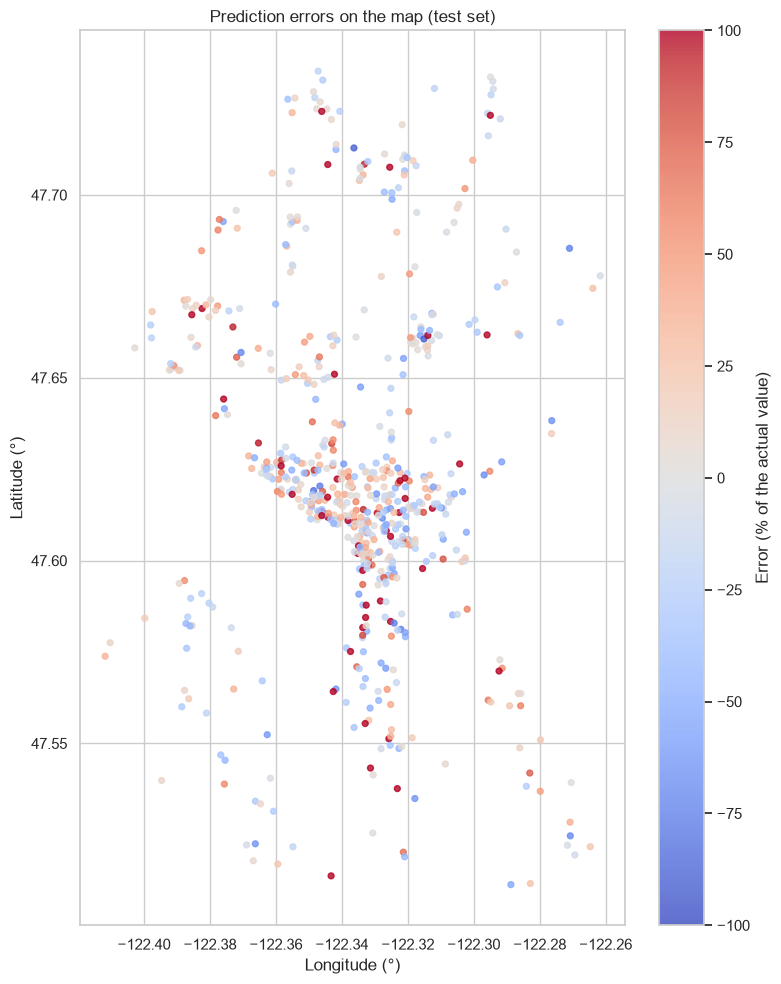

In [20]:
#map of the test buildings coloured by the error (cut at -100% / +100% so the colours stay readable)
map_df = pd.DataFrame({
    "longitude": X_test["longitude"],
    "latitude": X_test["latitude"],
    "error (%)": percent_error.clip(-100, 100),
})

fig, ax = plt.subplots(figsize=(8, 10))
points = ax.scatter(map_df["longitude"], map_df["latitude"], c=map_df["error (%)"],
                    cmap="coolwarm", vmin=-100, vmax=100, s=18, alpha=0.8)
fig.colorbar(points, ax=ax, label="Error (% of the actual value)")
ax.set_title("Prediction errors on the map (test set)")
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_error_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
#median error per neighborhood (signed: below 0 = underestimated)
hood_df = pd.DataFrame({
    "neighborhood": X_test["neighborhood"],
    "error (%)": percent_error,
})
hood_df.groupby("neighborhood")["error (%)"].agg(["count", "median"]).sort_values("median")

,count,median
neighborhood,,
CENTRAL,24,-16.926
DELRIDGE,14,-12.151
SOUTHWEST,23,-10.814
GREATER DUWAMISH,72,-9.863
NORTH,29,-5.903
EAST,93,-5.147
NORTHEAST,45,-4.652
NORTHWEST,41,4.167
MAGNOLIA / QUEEN ANNE,86,4.218


The north, mostly housing, is lighter, so the errors there are smaller. The strong <span style="color:#b40426"><b>reds</b></span> and <span style="color:#3b4cc0"><b>blues</b></span> are mostly in the industrial strip in the south, where there are lots of warehouses and "Other" buildings, and downtown, where the uses are mixed.

Per neighborhood the model overestimates Ballard and Southeast (around +20%) and underestimates Central (around -17%), and Delridge, Southwest and Greater Duwamish (around -10%). The model barely uses the location (see the importance below), so it can't correct for these areas.

# 6. Interpretation
Permutation importance: we shuffle one column at a time in the test set and see how much the R2 drops. A big drop means the model really uses that column.

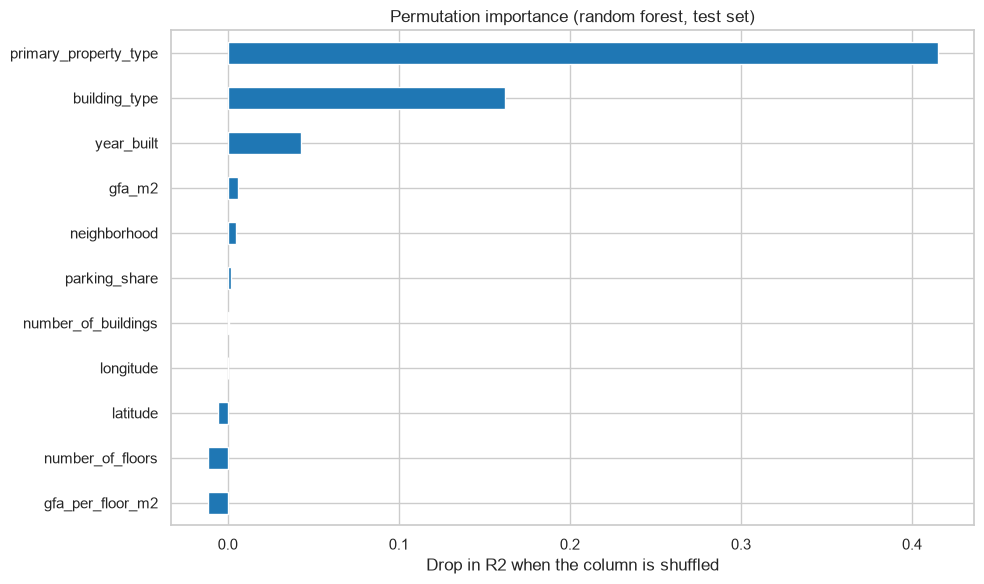

primary_property_type    0.415
building_type            0.162
year_built               0.043
gfa_m2                   0.006
neighborhood             0.005
parking_share            0.002
number_of_buildings      0.001
longitude               -0.000
latitude                -0.006
number_of_floors        -0.011
gfa_per_floor_m2        -0.012
dtype: float64

In [22]:
#permutation importance on the test set
importance = permutation_importance(best_model, X_test, y_test, scoring="r2",
                                    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance_series = pd.Series(importance.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
importance_series.plot.barh(ax=ax, color="tab:blue")
ax.set_title("Permutation importance (random forest, test set)")
ax.set_xlabel("Drop in R2 when the column is shuffled")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

importance_series.sort_values(ascending=False)

The model mostly relies on the use of the building, then the building type, and a bit on the year built. Size and location almost don't matter (a few are even slightly below 0, which just means shuffling them didn't hurt). It's the same thing we saw in the EDA: what the building is used for decides most of its energy. For an architect, the shape of the building barely moves the estimate in this model. This shows what the model uses, not what causes the energy use.

# 7. Save and reuse the model
We save the whole pipeline (preprocessing + model), so it can be used directly on a table with the same columns.

In [23]:
#save the fitted pipeline
model_path = MODEL_DIR / "model.joblib"
joblib.dump(best_model, model_path)
print(f"Saved to {model_path} ({model_path.stat().st_size / 1e6:.1f} MB)")

Saved to ../models/model.joblib (46.7 MB)


In [24]:
#load it again and try a new building: a 6 floor apartment block in the east of the city
loaded_model = joblib.load(model_path)

#check the saved model gives the same predictions as before
assert (loaded_model.predict(X_test) == y_pred).all()


new_building = pd.DataFrame({
    "primary_property_type": ["Mid-Rise Multifamily"],
    "building_type": ["Multifamily MR (5-9)"],
    "neighborhood": ["EAST"],
    "year_built": [2016],
    "number_of_floors": [6],
    "number_of_buildings": [1],
    "gfa_m2": [6000],
    "gfa_per_floor_m2": [1000],
    "parking_share": [0.1],
    "latitude": [47.615],
    "longitude": [-122.315],
})

prediction = loaded_model.predict(new_building)
print(f"Predicted energy use: {10 ** prediction[0]:.0f} kWh/m2 per year")

Predicted energy use: 89 kWh/m2 per year


The model gives about 89 kWh/m2 a year for this apartment block, so around 530,000 kWh a year for the whole 6,000 m2. With a typical error around 45%, it's a rough first idea, not an exact number.

# 8. Conclusions

### What we found
- The tuned random forest is the best model: on the test set R2 0.39 and typical error around 45% (MAE 68 kWh/m2, the baseline is at 89).
- Ridge is almost as good and much faster and simpler.
- The use of the building matters the most, then the building type.
- Gas would add about 0.05 to the R2, but we left it out because in this data it comes from the bills.
- It works best for housing and worst for warehouses and "Other" (around 50% error).

### Final model
The tuned random forest. The gap with Ridge is small, but it's the best score. If the model had to be fast, light or easy to explain to a client, Ridge would be the better choice: it trains in 0.01 s instead of 1.6 s, and the saved forest is 47 MB.

### What we would do differently
- Test on the newest buildings instead of a random split, to see how it does on really new ones.
- Look for data on how the buildings are used (hours, people) and on the planned heating, that's what the model is missing.

### Limitations
- With an R2 of 0.39 it explains less than half of the differences. Energy depends a lot on how the building is used (hours, equipment, people), and we don't have that.
- It pulls predictions towards the middle, so it underestimates the buildings that use the most energy.
- Only big buildings in Seattle, in 2016, so only Seattle's climate.
- The split is random, so we test on existing buildings mixed with the training ones, not on buildings built later. Real new buildings could do worse.
- The data is reported by the owners, the city checks it but there can still be mistakes.
- Don't use it for data centers, labs or very mixed buildings, or as an exact number for a design decision. It's a first estimate.